# Exercise 14.1 – Tool wear failure

Status: **SCIENTIFICALLY APPROVED – TECHNICALLY VALIDATED – AWAITING FINAL MERGE AUTHORIZATION**. KI-Unterstützung: Codex (Umsetzung und technische Prüfung); Studentischer Human Review positiv; finale Merge-Autorisierung steht aus.

## 1. Ziel der Aufgabe
Die [offizielle Aufgabe 14.1](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/1_self_study_session1.html) verlangt, den Widerspruch zwischen der TWF-Beschreibung in **13.1.7** und den Befunden aus **13.1.6.1/13.1.6.2** zu identifizieren. Quellen gelesen am **19.11.2026**.

Abnahmepunkte: Originaldaten prüfen; TWF-Anzahl und Verschleißbereich mit der Beschreibung vergleichen; den Kursbefund bei 202,5 min nachzählen und Grenzen erklären. Ein neues Modell oder die OSF-/HDF-/PWF-Analysen aus 14.2/14.3 sind nicht erforderlich.

## 2. Datengrundlage
[AI4I 2020, UCI](https://doi.org/10.24432/C5HS5C), synthetische Daten, **CC BY 4.0**. Die vorhandene Original-CSV wird per SHA256 geprüft und vollständig geladen. `TWF=1` kennzeichnet Tool Wear Failure; `Machine failure` ist das allgemeine Fehlerflag. `TWF=0` bedeutet nur, dass dieser Fehlertyp nicht markiert ist. HDF, PWF, OSF und RNF bezeichnen andere Fehlertypen, die hier nicht weiter untersucht werden.

`Tool wear [min]` ist die aufgezeichnete Werkzeugverschleißdauer. UDI dient zur Zeilenidentifikation, nicht als gesicherter Zeitstempel. Die folgende Tabelle zeigt alle Datentypen und fehlenden Werte.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))
from sessions.ch14.tool_wear import WEAR, load_data, wear_tables
from sessions.ch10.ai4i_data import verify_file

output = root / "outputs/ch14/exercise_14_1"
output.mkdir(parents=True, exist_ok=True)
data = load_data()
quality = pd.DataFrame({"Datentyp": data.dtypes.astype(str), "Fehlende Werte": data.isna().sum()})
quality.index.name = "Spalte"
quality.to_csv(output / "data_quality.csv")
print(f"{len(data):,} Zeilen, {data.shape[1]} Spalten; vollständige Duplikate: {data.duplicated().sum()}")
print("Rohdaten-SHA256:", verify_file())
display(quality)

10,000 Zeilen, 14 Spalten; vollständige Duplikate: 0
Rohdaten-SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e


,Datentyp,Fehlende Werte
Spalte,,
UDI,int64,0
Product ID,object,0
Type,object,0
Air temperature [K],float64,0
Process temperature [K],float64,0
Rotational speed [rpm],int64,0
Torque [Nm],float64,0
Tool wear [min],int64,0
Machine failure,int64,0


## 3. Vorgehensweise
Wir zählen die Markierungen direkt, ohne Modelltraining. Die Beschreibung in [13.1.7](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/0_0_predictive_maintenance.html#sec-act2-1-reveal) nennt einen zufällig bestimmten Austausch oder Ausfall bei **200–240 min**, davon **51 Ausfälle** und **69 Austausche**.

Wir prüfen den Bereich einschließlich beider Grenzen. Zusätzlich zählen wir am **vorgegebenen** Kurs-Trennwert 202,5 min; dieser wird hier nicht neu geschätzt. Da keine Vorhersage oder Parametersuche erfolgt, ist kein TRAIN-/TEST-Split erforderlich.

## 4. Ergebnisse

In [2]:
bands, threshold, outside = wear_tables(data)
twf_wear = data.loc[data.TWF.eq(1), WEAR]
summary = {
    "rows": len(data), "columns": data.shape[1],
    "missing_values": int(data.isna().sum().sum()),
    "duplicate_rows": int(data.duplicated().sum()),
    "twf_count": len(twf_wear), "description_claim": 51,
    "minimum_twf_wear": int(twf_wear.min()), "maximum_twf_wear": int(twf_wear.max()),
    "outside_interval": len(outside), "at_or_below_200": int((twf_wear <= 200).sum()),
    "twf_with_general_failure": int(data.loc[data.TWF.eq(1), "Machine failure"].sum()),
    "other_general_failures": int(((data.TWF == 0) & (data["Machine failure"] == 1)).sum()),
}
for name, table in [("wear_bands", bands), ("threshold_comparison", threshold), ("twf_outside_interval", outside)]:
    print(name)
    display(table)
    table.to_csv(output / f"{name}.csv", index=False)
(output / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print(f"TWF-Markierungen: {summary['twf_count']} statt der beschriebenen 51.")
print(f"TWF-Verschleißbereich: {summary['minimum_twf_wear']}–{summary['maximum_twf_wear']} min.")
print(f"Alle {summary['twf_count']} TWF-Fälle haben Machine failure=1; weitere {summary['other_general_failures']} allgemeine Fehler haben TWF=0.")

wear_bands


,Bereich,Datensätze,TWF=1,TWF=0
0,< 200 min,9199,1,9198
1,200–240 min (einschließlich),790,43,747
2,> 240 min,11,2,9


threshold_comparison


,Bereich,Datensätze,TWF=1,TWF=0
0,"≤ 202,5 min",9328,2,9326
1,"> 202,5 min",672,44,628


twf_outside_interval


Spalte,UDI,Tool wear [min],TWF,Machine failure
1996,1997,198,1,1
2864,2865,246,1,1
5401,5402,253,1,1


TWF-Markierungen: 46 statt der beschriebenen 51.
TWF-Verschleißbereich: 198–253 min.
Alle 46 TWF-Fälle haben Machine failure=1; weitere 293 allgemeine Fehler haben TWF=0.


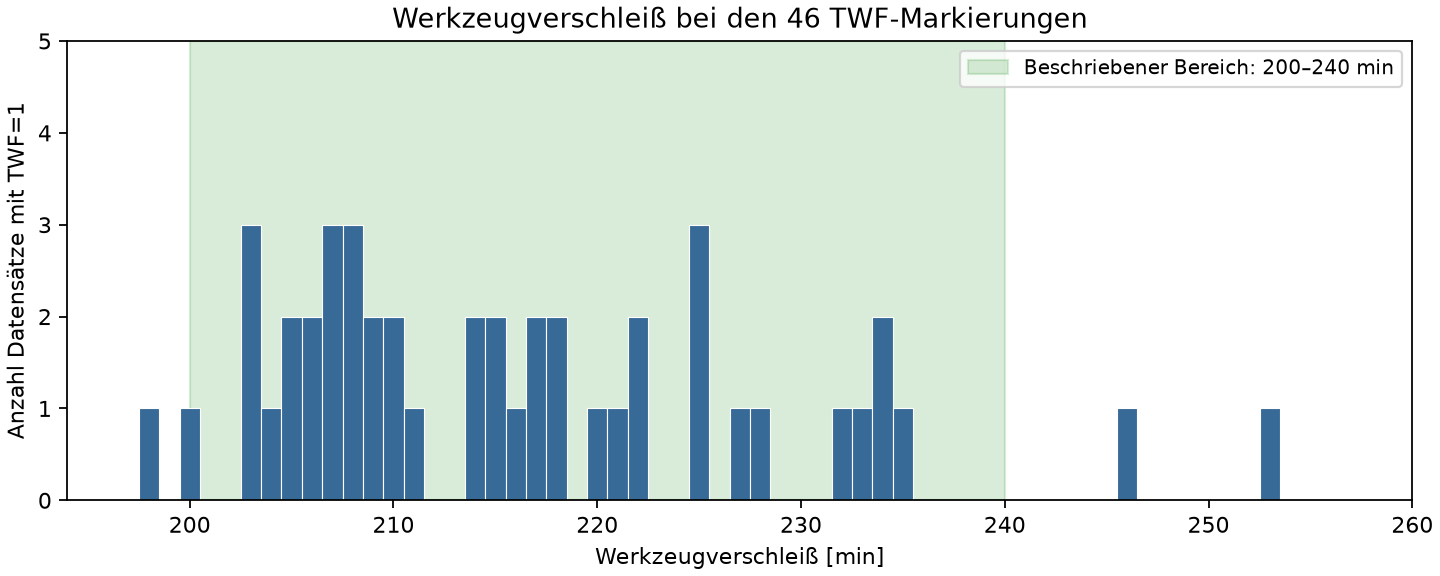

In [3]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ax.axvspan(200, 240, alpha=0.15, color="green", label="Beschriebener Bereich: 200–240 min")
ax.hist(twf_wear, bins=np.arange(194.5, 260.5, 1), color="#386a98", edgecolor="white", linewidth=0.5)
ax.set(title=f"Werkzeugverschleiß bei den {len(twf_wear)} TWF-Markierungen",
       xlabel="Werkzeugverschleiß [min]", ylabel="Anzahl Datensätze mit TWF=1", xlim=(194, 260))
ax.set_yticks(range(0, 6))
ax.legend(fontsize=9)
fig.savefig(output / "01_twf_wear.png", dpi=160)
plt.close(fig)
display(Image(filename=str(output / "01_twf_wear.png")))

Die Grafik zeigt ausschließlich TWF-markierte Datensätze. Ihre Balkenbreite entspricht einer Minute; sie stellt keine Ausfallwahrscheinlichkeit dar. Die Tabelle enthält zusätzlich die Vergleichsgruppen mit `TWF=0`.

## 5. Kurze Interpretation
**Beobachtung:** Die CSV enthält **46 statt 51 TWF-Markierungen**. Davon liegen **43 innerhalb** von 200–240 min; die übrigen drei bei **198, 246 und 253 min**. Auch die Aussage „TWF nur oberhalb von 200 min“ ist wörtlich zu stark: Ein Fall liegt bei 198 min, einer bei genau 200 min.

Der konkrete Baumbefund aus 13.1.6.2 wird dagegen bestätigt: **2 TWF-Fälle unterhalb beziehungsweise bei 202,5 min unter 9.328 Datensätzen**, gegenüber **44 unter 672 darüber**. Die Häufung bei hohem Verschleiß ist damit nachvollziehbar; ein hohes Verschleißniveau bedeutet aber nicht automatisch TWF.

**Antwort auf 14.1:** Die Beschreibung stimmt hinsichtlich der genannten Ausfallanzahl und des strikt abgegrenzten Zeitbereichs nicht vollständig mit den gelieferten Markierungen überein. Der grundsätzliche Zusammenhang mit hohem Verschleiß bleibt bestehen.

## 6. Wissenschaftliche Grenzen
Die CSV enthält kein eigenes Austauschflag. Deshalb lassen sich die beschriebenen **69 Austausche** nicht einfach aus `TWF=0` nachweisen. Ebenso belegt die Prüfung keine zufällige Zuweisung und erklärt nicht die Ursache der Abweichung. Insbesondere wäre eine Vermutung über den Zeitpunkt der Verschleißaufzeichnung noch kein Beweis.

Wir erhalten alle Originalwerte und Labels unverändert. Eine Abweichung von der Beschreibung macht einen einzelnen Datensatz nicht automatisch zu einem Messfehler. Die synthetischen Daten und diese deskriptive Prüfung erlauben keine neue Kausalaussage oder Aussage über reale Maschinen. Es wurde weder ein neuer Baum trainiert noch eine Modellgüte geschätzt.

**Reproduktion vom Projektstamm:** `scripts/uv.cmd run --offline --locked python scripts/build_exercise_14_1.py --check-html`. Python/uv und Abhängigkeiten sind im bestehenden Projekt festgelegt. Falls die Roh-CSV fehlt, zuerst `scripts/download_ai4i.py` ausführen. Notebook plus HTML sind die vorgesehenen Lesedateien; 14.1 verlangt keinen PDF-Export.